# Homework07

Exercises to practice pandas, data analysis and regression

## Goals

- Understand the effects of pre-processing data
- Get familiar with the ML flow: encode -> normalize -> train -> evaluate
- Understand the difference between regression and classification tasks
- Build intuition for different regression models

### Setup

Run the following 2 cells to import all necessary libraries and helpers for this homework.

In [1]:
!wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/data_utils.py" -O data_utils.py

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, SGDRegressor

from data_utils import object_from_json_url
from data_utils import regression_error

### Load Dataset

Let's load up the full [ANSUR](https://www.openlab.psu.edu/ansur2/) dataset that we looked at briefly in [Week 02](https://github.com/DM-GY-9103-2024F-H/WK02).

This is the dataset that has anthropometric information about U.S. Army personnel.

#### WARNING

Like we mentioned in class, this dataset is being used for these exercises due to the level of detail in the dataset and the rigorous process that was used in collecting the data.

This is a very specific dataset and should not be used to draw general conclusions about people, bodies, or anything else that is not related to the distribution of physical features of U.S. Army personnel.

In [3]:
# Load Dataset
ANSUR_FILE = "https://raw.githubusercontent.com/PSAM-5020-2026F-A/5020-utils/main/datasets/json/ansur.json"
ansur_data = object_from_json_url(ANSUR_FILE)

# Look at first 2 records
ansur_data[:2]

[{'age': 18,
  'gender': 'F',
  'height': 66,
  'weight': 135,
  'span': 1699,
  'stature': 1645,
  'ear': {'breadth': 30, 'length': 61, 'protrusion': 20},
  'foot': {'breadth': 97, 'length': 243},
  'hand': {'breadth': 78, 'length': 182, 'palm': 108},
  'head': {'height': 243, 'circumference': 557}},
 {'age': 30,
  'gender': 'M',
  'height': 68,
  'weight': 207,
  'span': 1749,
  'stature': 1715,
  'ear': {'breadth': 35, 'length': 63, 'protrusion': 17},
  'foot': {'breadth': 100, 'length': 252},
  'hand': {'breadth': 87, 'length': 184, 'palm': 114},
  'head': {'height': 238, 'circumference': 560}}]

#### Nested data

This is that *nested* dataset from Week 02.

# 🤔

Let's load it into a `DataFrame` to see what happens.

In [4]:
# Read into DataFrame
ansur_df = pd.DataFrame.from_records(ansur_data)
ansur_df.head()

,age,gender,height,weight,span,stature,ear,foot,hand,head
0,18,F,66,135,1699,1645,"{'breadth': 30, 'length': 61, 'protrusion': 20}","{'breadth': 97, 'length': 243}","{'breadth': 78, 'length': 182, 'palm': 108}","{'height': 243, 'circumference': 557}"
1,30,M,68,207,1749,1715,"{'breadth': 35, 'length': 63, 'protrusion': 17}","{'breadth': 100, 'length': 252}","{'breadth': 87, 'length': 184, 'palm': 114}","{'height': 238, 'circumference': 560}"
2,27,M,67,121,1684,1657,"{'breadth': 36, 'length': 59, 'protrusion': 24}","{'breadth': 92, 'length': 251}","{'breadth': 84, 'length': 180, 'palm': 103}","{'height': 239, 'circumference': 516}"
3,20,M,73,185,1878,1828,"{'breadth': 36, 'length': 60, 'protrusion': 21}","{'breadth': 104, 'length': 280}","{'breadth': 95, 'length': 201, 'palm': 124}","{'height': 270, 'circumference': 582}"
4,33,M,76,150,1977,1883,"{'breadth': 39, 'length': 65, 'protrusion': 27}","{'breadth': 101, 'length': 271}","{'breadth': 90, 'length': 194, 'palm': 113}","{'height': 254, 'circumference': 559}"



# 😓🙄

That didn't work too well. We ended up with objects in our columns.

Luckily, our `DataFrame` library has a function called [`json_normalize()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.json_normalize.html) that can help.

In [5]:
# Read into DataFrame
ansur_df = pd.json_normalize(ansur_data)
ansur_df.head()

,age,gender,height,weight,span,stature,ear.breadth,ear.length,ear.protrusion,foot.breadth,foot.length,hand.breadth,hand.length,hand.palm,head.height,head.circumference
0,18,F,66,135,1699,1645,30,61,20,97,243,78,182,108,243,557
1,30,M,68,207,1749,1715,35,63,17,100,252,87,184,114,238,560
2,27,M,67,121,1684,1657,36,59,24,92,251,84,180,103,239,516
3,20,M,73,185,1878,1828,36,60,21,104,280,95,201,124,270,582
4,33,M,76,150,1977,1883,39,65,27,101,271,90,194,113,254,559


Much better. `DataFrames` are magic.

#### Data Exploration

Before we start creating models, let's do a little bit of data analysis and get a feeling for the shapes, distributions and relationships of our data.

1. Print `min`, `max` and `average` values for all of the features.
2. Print `covariance` tables for `age`, `ear.length` and `head.circumference`.
3. Plot `age`, `ear.length` and `head.circumference` versus the $1$ *feature* that is most correlated to each of them.

Don't forget to *encode* and *normalize* the data.

                       min     max      average
age                   17.0    58.0    29.745357
gender                 0.0     1.0     0.672679
height                56.0    94.0    68.247321
weight                 0.0   321.0   174.558393
span                1323.0  2121.0  1763.703393
stature             1409.0  1993.0  1714.265357
ear.breadth           25.0    46.0    35.128929
ear.length            46.0    81.0    62.637143
ear.protrusion        13.0    34.0    22.266786
foot.breadth          77.0   126.0    98.850893
foot.length          198.0   323.0   262.991964
hand.breadth          67.0   105.0    84.936964
hand.length          145.0   239.0   189.260179
hand.palm             88.0   140.0   113.919643
head.height          206.0   295.0   249.170893
head.circumference   502.0   635.0   570.062857

Covariance with age:
                         age
age                 1.000179
gender              0.062201
height              0.029467
weight              0.217017
span             

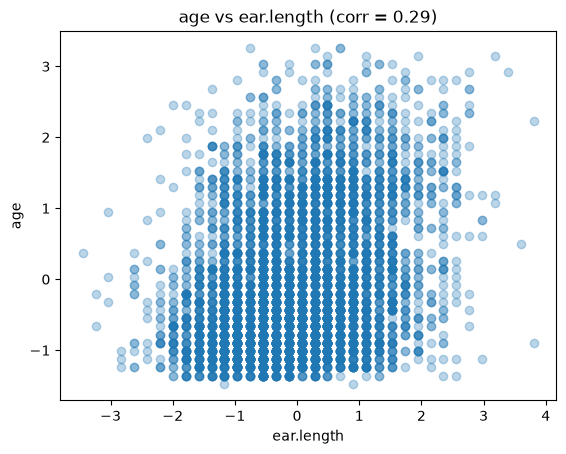

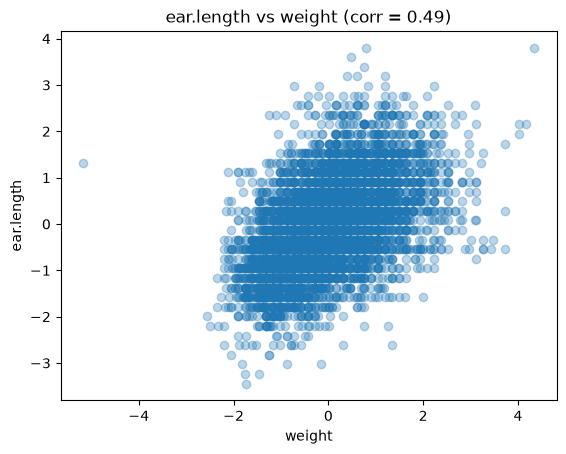

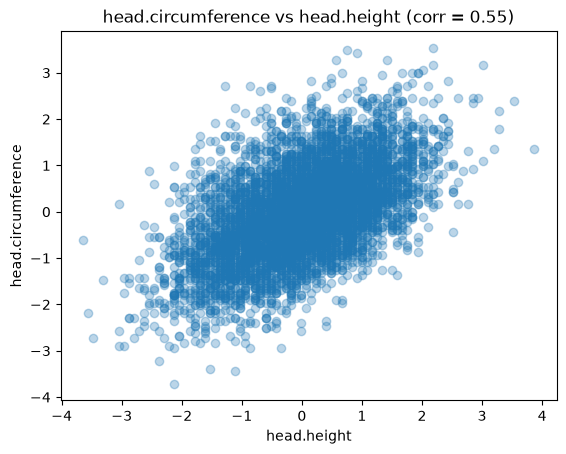

In [10]:
# Work on Data Exploration here

### Encode non-numerical features
encoded_df = ansur_df.copy()

ansur_encoder = OrdinalEncoder()
gender_column = encoded_df[["gender"]]
encoded_gender = ansur_encoder.fit_transform(gender_column)
encoded_df["gender"] = encoded_gender

## 1. Print min, max, avg
min_values = encoded_df.min()
max_values = encoded_df.max()
avg_values = encoded_df.mean()

summary_df = pd.DataFrame({
    "min": min_values,
    "max": max_values,
    "average": avg_values,
})
print(summary_df)


### Normalize all data
ansur_scaler = StandardScaler().set_output(transform="pandas")
normalized_df = ansur_scaler.fit_transform(encoded_df)

normalized_df = pd.DataFrame(
    scaled_values,
    columns=encoded_df.columns,
)

## 2. Print Covariances
target_features = ["age", "ear.length", "head.circumference"]
cov_matrix = normalized_df.cov()

for target in target_features:
    target_cov = cov_matrix[[target]]
    print(f"\nCovariance with {target}:")
    print(target_cov)


## 3. Plot features most correlated to age, ear length and head circumference
corr_matrix = normalized_df.corr()

for target in target_features:
    target_corr = corr_matrix[target]
    target_corr = target_corr.drop(target)
    abs_corr = target_corr.abs()
    best_feature = abs_corr.idxmax()
    best_corr_value = target_corr[best_feature]

    x_values = normalized_df[best_feature]
    y_values = normalized_df[target]

    plt.figure()
    plt.scatter(x_values, y_values, alpha=0.3)
    plt.xlabel(best_feature)
    plt.ylabel(target)
    plt.title(f"{target} vs {best_feature} (corr = {best_corr_value:.2f})")
    plt.show()

### Interpretation

<span style="color:hotpink;">
Does anything stand out about these graphs? Or the correlations?<br>
Are correlations symmetric? Does the feature most correlated to ear length also have ear length as its most correlated pair?
</span>

The correlations are all weak to moderate and none is close to 1. Age is the weakest, with its best partner (ear.length) only reaching 0.29, which makes sense because age doesn't track body size in adult. The age plot also shows vertical stripes because ear.length is measured in whole millimeters, so the data is discrete. The strongest partners aren't always the obvious ones.ear.length is most correlated with weight (0.49) rather than another ear measurement, while head.circumference is most correlated with head.height (about 0.55). Correlation between any two features seems symmetric, meaning corr(A, B) equals corr(B, A), but most correlated feature is not symmetric. Weight has other features it correlates with more strongly than ear.length, so ear.length's top match doesn't have ear.length as its own top match.

### Regression

Now, we want to create a regression model to predict `head.circumference` from the data.

From our [Week 07](https://github.com/PSAM-5020-2026F-A/WK07) notebook, we can create a regression model by following these steps:

1. Load dataset (done! 🎉)
2. Encode label features as numbers (done! ⚡️)
3. Normalize the data (done! 🍾)
4. Separate the outcome variable and the input features
5. Create a regression model using all features
6. Run model on training data and measure error
7. Plot predictions and interpret results
8. Run model on test data, measure error, plot predictions, interpret results

Training error (mm): 13.910571985204236


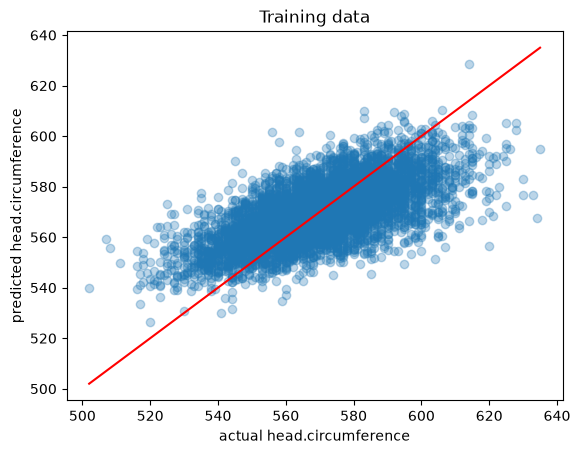

In [11]:
# Work on Regression Model here

## Separate outcome variable and input features
outcome_name = "head.circumference"
outcome = encoded_df[[outcome_name]]
features = normalized_df.drop(columns=[outcome_name])

## Create a regression model
model = LinearRegression()
model.fit(features, outcome)

## Measure error on training data
predicted = model.predict(features)
actual_values = encoded_df[outcome_name]
train_error = regression_error(actual_values, predicted)
print("Training error (mm):", train_error)

## Plot predictions and interpret results
predicted_flat = predicted.ravel()
low_value = actual_values.min()
high_value = actual_values.max()

plt.scatter(actual_values, predicted_flat, alpha=0.3)
plt.plot([low_value, high_value], [low_value, high_value], color="red")
plt.xlabel("actual head.circumference")
plt.ylabel("predicted head.circumference")
plt.title("Training data")
plt.show()

In [12]:
## Load Test Data
ANSUR_TEST_FILE = "https://raw.githubusercontent.com/PSAM-5020-2026F-A/5020-utils/main/datasets/json/ansur-test.json"

ansur_test_data = object_from_json_url(ANSUR_TEST_FILE)
ansur_test_df = pd.json_normalize(ansur_test_data)

ansur_test_encoded_df = ansur_test_df.copy()

g_vals = ansur_encoder.transform(ansur_test_df[["gender"]])
ansur_test_encoded_df[["gender"]] = g_vals

ansur_test_scaled_df = ansur_scaler.transform(ansur_test_encoded_df)

Test error (mm): 14.4732380584235


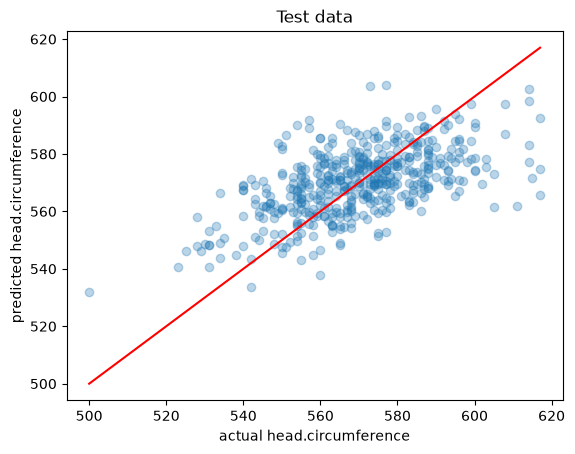

In [13]:
## Run model on test data
test_actual_values = ansur_test_encoded_df[outcome_name]
test_features = ansur_test_scaled_df.drop(columns=[outcome_name])
test_predicted = model.predict(test_features)

## Measure error on test data
test_error = regression_error(test_actual_values, test_predicted)
print("Test error (mm):", test_error)

## Plot predictions and interpret results
test_predicted_flat = test_predicted.ravel()
low_value = test_actual_values.min()
high_value = test_actual_values.max()

plt.scatter(test_actual_values, test_predicted_flat, alpha=0.3)
plt.plot([low_value, high_value], [low_value, high_value], color="red")
plt.xlabel("actual head.circumference")
plt.ylabel("predicted head.circumference")
plt.title("Test data")
plt.show()

### Interpretation

<span style="color:hotpink;">
How well does your model perform?<br>
How could you improve it?<br>
Are there ranges of circumferences that don't get predicted well?
</span>

I think the model does a pretty good job. On average, its guesses for head circumference are off by about 14 mm, which is small compared to a typical head size of around 570 mm. The error on the training data (13.9 mm) and the test data (14.5 mm) are almost the same, which means the model works about as well on new data as on the data it learned from. Looking at the graphs, the model is not good at the very small and very large circumferences. For small heads (around 500-530 mm) it guesses too high, and for large heads (600 mm and above) it guesses too low. This is probably because there are not many examples of very small or very large heads in the data. To make the model better, we could add more features or more data, especially examples of very small and very large heads.